# Activation Functions Exercise

In this exercise, we will implement the forward and backward propagation of common activation functions . These functions are essential building blocks in neural networks and understanding their implementation will provide valuable insights into how neural networks operate.

We will start by implementing the sigmoid and tanh activation functions, which are widely used in various neural network architectures. Each function will have a forward pass that computes the output and a backward pass that computes the gradients with respect to the inputs.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from annp.classifiers.fc_net import *
from annp.gradient_check import eval_numerical_gradient_array

%matplotlib inline
plt.rcParams['figure.figsize'] = (10.0, 8.0)


def rel_error(x, y):
    return np.max(np.abs(x - y) / (np.maximum(1e-8, np.abs(x) + np.abs(y))))



## Tanh activation: forward
Implement the forward pass for the Tanh activation function `tanh_forward` in the `annp/layers.py` and test your implementation using the following:

In [2]:
# Test the tanh_forward function

x = np.linspace(-1, 1, num=10).reshape(5, 2)

out, _ = tanh_forward(x)
correct_out = np.array([[-0.76159416, -0.65142936],
                        [-0.5046724,  -0.32151274],
                        [-0.11065611,  0.11065611],
                        [ 0.32151274,  0.5046724 ],
                        [ 0.65142936,  0.76159416]])

# Compare your output with the direct calculation. The error should be on the order of e-8 or less
print('Testing tanh_forward function:')
print('difference: ', rel_error(out, correct_out))

Testing tanh_forward function:
difference:  3.838674858587434e-09


## Tanh activation: backward
Now implement the backward pass for the Tanh activation function in the `tanh_backward` function and test your implementation using numeric gradient checking:

In [4]:
np.random.seed(231)
x = np.random.randn(10, 10)
dout = np.random.randn(*x.shape)

dx_num = eval_numerical_gradient_array(lambda x: tanh_forward(x)[0], x, dout)

_, cache = tanh_forward(x)
dx = tanh_backward(dout, cache)

# The error should be on the order of e-12 or less
print('Testing tanh_backward function:')
print('dx error: ', rel_error(dx_num, dx))

Testing tanh_backward function:
dx error:  1.0409584283255793e-10


## Sigmoid activation: forward
Implement the forward pass for the Sigmoid activation function in the `sigmoid_forward` function and test your implementation using the following:

In [6]:
# Test the sigmoid_forward function

x = np.linspace(-1, 1, num=10).reshape(5, 2)

out, _ = sigmoid_forward(x)
correct_out = np.array([[0.26894142,0.31479902],
                        [0.36457644, 0.41742979],
                        [0.47225076, 0.52774924],
                        [0.58257021, 0.63542356],
                        [0.68520098, 0.73105858]])

# Compare your output with the direct calculation. The error should be on the order of e-8 or less
print('Testing sigmoid_forward function:')
print('difference: ', rel_error(out, correct_out))

Testing sigmoid_forward function:
difference:  5.296529106595102e-09


## Sigmoid activation: backward
Now implement the backward pass for the Sigmoid activation function in the `sigmoid_backward` function and test your implementation using numeric gradient checking:

In [8]:
np.random.seed(231)
x = np.random.randn(10, 10)
dout = np.random.randn(*x.shape)

dx_num = eval_numerical_gradient_array(lambda x: sigmoid_forward(x)[0], x, dout)

_, cache = sigmoid_forward(x)
dx = sigmoid_backward(dout, cache)

# The error should be on the order of e-12 or less
print('Testing sigmoid_backward function:')
print('dx error: ', rel_error(dx_num, dx))

Testing sigmoid_backward function:
dx error:  3.446520386706568e-11


## Visualization: Activation Functions and Their Derivatives

Visualize the sigmoid and tanh activation functions along with their derivatives to better understand their properties.

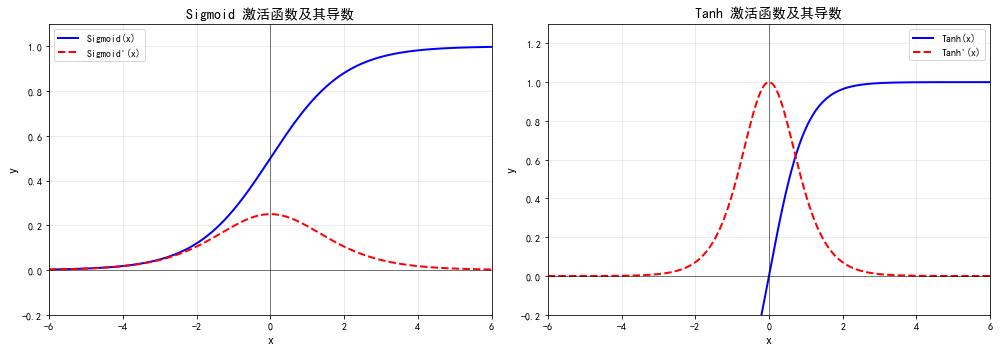

✅ 图片已保存到: img/activation_functions.png


In [9]:
# ============================================================
# 激活函数可视化 - 保存到 img/ 文件夹
# ============================================================

import os
os.makedirs('img', exist_ok=True)

# 设置中文字体支持
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'Arial Unicode MS']
plt.rcParams['axes.unicode_minus'] = False

# 生成输入数据
x = np.linspace(-6, 6, 500)

# 计算前向传播输出
sigmoid_out, sigmoid_cache = sigmoid_forward(x)
tanh_out, tanh_cache = tanh_forward(x)

# 计算导数（反向传播）
# Sigmoid 导数: sigmoid(x) * (1 - sigmoid(x))
sigmoid_deriv = sigmoid_out * (1 - sigmoid_out)
# Tanh 导数: 1 - tanh(x)^2
tanh_deriv = 1 - tanh_out ** 2

# 创建图形
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Sigmoid 激活函数
axes[0].plot(x, sigmoid_out, 'b-', linewidth=2, label='Sigmoid(x)')
axes[0].plot(x, sigmoid_deriv, 'r--', linewidth=2, label="Sigmoid'(x)")
axes[0].axhline(y=0, color='k', linestyle='-', linewidth=0.5)
axes[0].axvline(x=0, color='k', linestyle='-', linewidth=0.5)
axes[0].set_xlabel('x', fontsize=12)
axes[0].set_ylabel('y', fontsize=12)
axes[0].set_title('Sigmoid 激活函数及其导数', fontsize=14)
axes[0].legend(loc='best', fontsize=10)
axes[0].grid(True, alpha=0.3)
axes[0].set_xlim(-6, 6)
axes[0].set_ylim(-0.2, 1.1)

# Tanh 激活函数
axes[1].plot(x, tanh_out, 'b-', linewidth=2, label='Tanh(x)')
axes[1].plot(x, tanh_deriv, 'r--', linewidth=2, label="Tanh'(x)")
axes[1].axhline(y=0, color='k', linestyle='-', linewidth=0.5)
axes[1].axvline(x=0, color='k', linestyle='-', linewidth=0.5)
axes[1].set_xlabel('x', fontsize=12)
axes[1].set_ylabel('y', fontsize=12)
axes[1].set_title('Tanh 激活函数及其导数', fontsize=14)
axes[1].legend(loc='best', fontsize=10)
axes[1].grid(True, alpha=0.3)
axes[1].set_xlim(-6, 6)
axes[1].set_ylim(-0.2, 1.3)

plt.tight_layout()
plt.savefig('img/activation_functions.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ 图片已保存到: img/activation_functions.png")